In [1]:
import os
import json
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import LogLocator, LogFormatterMathtext

%matplotlib inline

SEED = 13
NOISE_LEVEL = 0.25
N_SAMPLES = 60
MAX_DEGREE = 15
OUTPUT_DIR = "."

np.random.seed(SEED)
os.makedirs(OUTPUT_DIR, exist_ok=True)

plt.rcParams.update({
    "font.family": "DejaVu Sans",
    "font.size": 9,
    "axes.titlesize": 10,
    "axes.labelsize": 9,
    "legend.fontsize": 7,
    "figure.dpi": 120,
    "savefig.dpi": 120,
    "axes.grid": True,
    "grid.alpha": 0.25,
})

print("Libraries imported and project configuration completed.")

Libraries imported and project configuration completed.


In [2]:
x = np.linspace(0, 1, N_SAMPLES)
x += np.random.uniform(-0.007, 0.007, N_SAMPLES)
x = np.clip(x, 0, 1)

y = np.sin(2 * np.pi * x)
y += np.random.normal(0, NOISE_LEVEL, N_SAMPLES)

data = pd.DataFrame({"x": x, "y": y})

display(data.head())
print("Total samples:", len(data))

,x,y
0,0.003888,-0.166583
1,0.013275,0.108628
2,0.038438,0.159857
3,0.057368,0.637282
4,0.074413,0.370170


Total samples: 60


In [3]:
train = data.sample(n=30, random_state=SEED)
validation = data.drop(train.index)

print("Training samples:", len(train))
print("Validation samples:", len(validation))

display(train.head())

Training samples: 30
Validation samples: 30


,x,y
33,0.559452,-0.558584
4,0.074413,0.370170
31,0.519484,0.391309
56,0.955116,0.054291
0,0.003888,-0.166583


In [4]:
def scale_x(values):
    return 2 * np.asarray(values) - 1

x_train = scale_x(train["x"])
y_train = train["y"].to_numpy()

x_val = scale_x(validation["x"])
y_val = validation["y"].to_numpy()

train = train.sort_values("x")
validation = validation.sort_values("x")

print("Training and validation arrays are ready.")

Training and validation arrays are ready.


In [5]:
results = []
models = {}

for degree in range(1, MAX_DEGREE + 1):
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        coefficients = np.polyfit(x_train, y_train, degree)

    models[degree] = coefficients

    train_predictions = np.polyval(coefficients, x_train)
    val_predictions = np.polyval(coefficients, x_val)

    train_rmse = float(np.sqrt(np.mean((y_train - train_predictions) ** 2)))
    val_rmse = float(np.sqrt(np.mean((y_val - val_predictions) ** 2)))
    largest_coefficient = float(np.max(np.abs(coefficients)))

    results.append({
        "degree": degree,
        "train_rmse": train_rmse,
        "validation_rmse": val_rmse,
        "largest_coefficient": largest_coefficient,
    })

error_table = pd.DataFrame(results)
display(error_table.round(4))

,degree,train_rmse,validation_rmse,largest_coefficient
0,1,0.5120,0.5411,0.8579
1,2,0.5106,0.5478,0.8646
2,3,0.2196,0.3162,3.4153
3,4,0.2140,0.3584,3.5038
4,5,0.2074,0.3054,5.1935
5,6,0.2012,0.2704,5.9492
6,7,0.1983,0.3206,9.7124
7,8,0.1982,0.3065,9.0816
8,9,0.1961,0.4118,30.5339
9,10,0.1941,0.2756,89.0276


In [6]:
best_row_index = error_table["validation_rmse"].idxmin()
best_degree = int(error_table.loc[best_row_index, "degree"])
best_val_rmse = float(error_table.loc[best_row_index, "validation_rmse"])

threshold = best_val_rmse * 1.10
eligible = error_table[error_table["validation_rmse"] <= threshold]
simplest_near_best = int(eligible["degree"].min())

degree_1 = error_table.loc[error_table["degree"] == 1].iloc[0]
degree_15 = error_table.loc[error_table["degree"] == 15].iloc[0]

ratio = (float(degree_15["validation_rmse"]) / best_val_rmse
         if best_val_rmse > 0 else float("inf"))

coef_degree_1 = float(degree_1["largest_coefficient"])
coef_degree_15 = float(degree_15["largest_coefficient"])

print("Best degree:", best_degree)
print(f"Best validation RMSE: {best_val_rmse:.4f}")
print("Simplest degree within 10% of best validation error:", simplest_near_best)

Best degree: 6
Best validation RMSE: 0.2704
Simplest degree within 10% of best validation error: 6


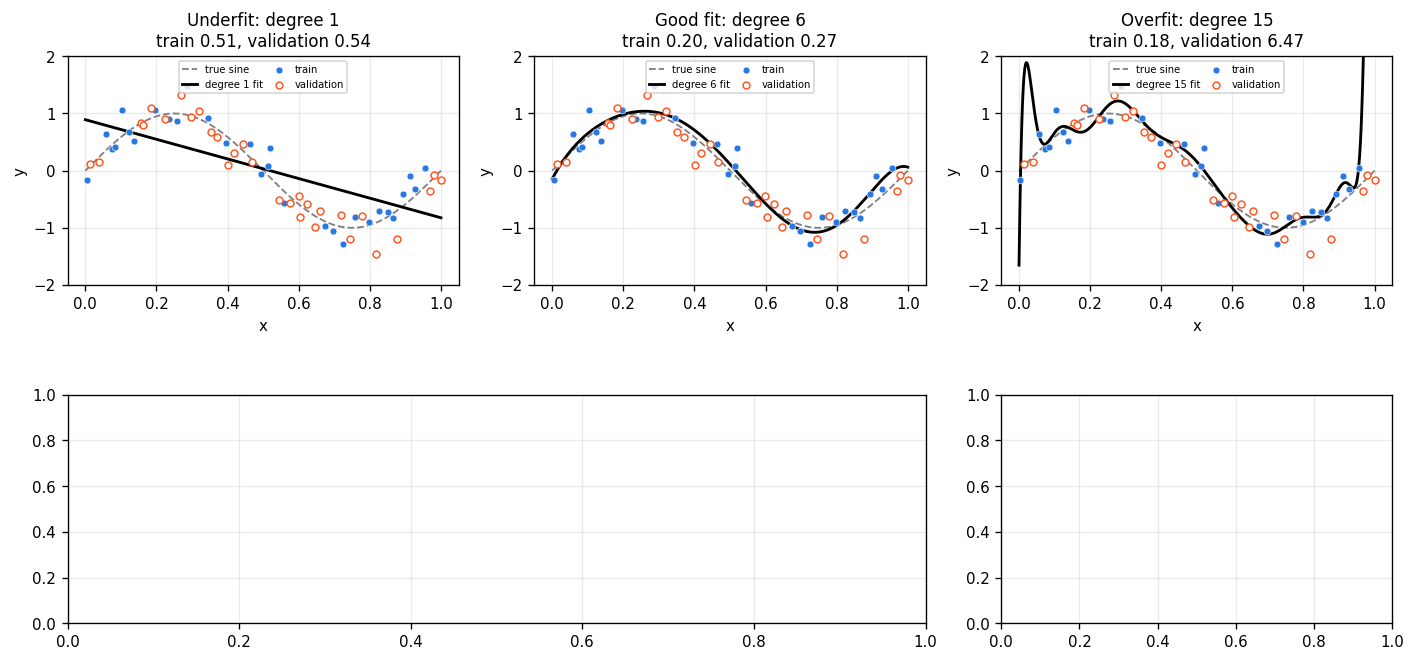

In [7]:
fig = plt.figure(figsize=(12, 6.3), constrained_layout=False)
gs = fig.add_gridspec(
    2, 6, left=0.065, right=0.985, top=0.92, bottom=0.17,
    wspace=0.48, hspace=0.48
)

ax_under = fig.add_subplot(gs[0, 0:2])
ax_good = fig.add_subplot(gs[0, 2:4])
ax_over = fig.add_subplot(gs[0, 4:6])
ax_error = fig.add_subplot(gs[1, 0:4])
ax_coef = fig.add_subplot(gs[1, 4:6])

x_plot = np.linspace(0, 1, 500)
x_plot_scaled = scale_x(x_plot)
y_true = np.sin(2 * np.pi * x_plot)

def plot_fit(ax, degree, title):
    coefficients = models[degree]
    predictions = np.polyval(coefficients, x_plot_scaled)
    row = error_table.loc[error_table["degree"] == degree].iloc[0]

    ax.plot(x_plot, y_true, color="gray", linestyle="--", linewidth=1.1, label="true sine")
    ax.plot(x_plot, predictions, color="black", linewidth=1.7, label=f"degree {degree} fit")
    ax.scatter(train["x"], train["y"], s=17, color="#2878E3",
               edgecolors="white", linewidths=0.35, label="train", zorder=3)
    ax.scatter(validation["x"], validation["y"], s=17, facecolors="white",
               edgecolors="#FF5722", linewidths=0.9, label="validation", zorder=3)

    ax.set_title(f"{title}\ntrain {row['train_rmse']:.2f}, validation {row['validation_rmse']:.2f}")
    ax.set_xlabel("x")
    ax.set_ylabel("y")
    ax.set_xlim(-0.05, 1.05)
    ax.set_ylim(-2, 2)
    ax.legend(loc="upper center", ncol=2, fontsize=6, frameon=True,
              borderpad=0.35, handlelength=1.5, columnspacing=0.8)

plot_fit(ax_under, 1, "Underfit: degree 1")
plot_fit(ax_good, best_degree, f"Good fit: degree {best_degree}")
plot_fit(ax_over, 15, "Overfit: degree 15")

plt.show()

In [8]:
degrees = error_table["degree"]
train_errors = error_table["train_rmse"]
val_errors = error_table["validation_rmse"]

ax_error.plot(degrees, train_errors, "-o", color="#2878E3", markersize=4,
              linewidth=1.2, label="train error")
ax_error.plot(degrees, val_errors, "-o", color="#FF5722", markersize=4,
              linewidth=1.2, label="validation error")
ax_error.axhline(NOISE_LEVEL, color="gray", linestyle=":", linewidth=1.2, label="noise level")
ax_error.axvline(best_degree, color="black", linestyle="--", linewidth=0.9)
ax_error.scatter([best_degree], [best_val_rmse], color="#2878E3", edgecolors="black", s=32, zorder=5)
ax_error.annotate(f"best degree = {best_degree}",
                  xy=(best_degree, best_val_rmse),
                  xytext=(best_degree + 0.35, best_val_rmse * 2.2),
                  arrowprops=dict(arrowstyle="->", linewidth=0.8), fontsize=8)
ax_error.set_title("Training error keeps falling, validation error turns up")
ax_error.set_xlabel("Polynomial degree")
ax_error.set_ylabel("RMSE (log scale)")
ax_error.set_yscale("log")
ax_error.set_xticks(range(1, MAX_DEGREE + 1))
ax_error.set_xlim(0.5, 15.7)
ax_error.legend(loc="upper left", frameon=True)

ax_coef.plot(degrees, error_table["largest_coefficient"], "-o", color="black",
             markersize=4, linewidth=1.2)
ax_coef.set_title("Why: coefficients explode")
ax_coef.set_xlabel("Polynomial degree")
ax_coef.set_ylabel("Largest coefficient (log scale)")
ax_coef.set_yscale("log")
ax_coef.set_xticks(range(2, MAX_DEGREE + 1, 2))
ax_coef.set_xlim(1.5, 15.5)

fig.text(0.5, 0.075,
         "Figure 20. Polynomial fits showing underfit, good fit and overfit, "
         "with training and validation error by degree and coefficient growth.",
         ha="center", va="center", fontsize=10, color="#555555", style="italic", wrap=True)
fig.text(0.5, 0.025, "Project 20  |  PAVITHRA P  |  Emp ID: TFTPL435",
         ha="center", va="center", fontsize=8, color="#555555")

plt.show()

chart_path = os.path.join(OUTPUT_DIR, "chart.png")
fig.savefig(chart_path, dpi=120, facecolor="white", bbox_inches="tight")
print("Chart saved to:", os.path.abspath(chart_path))

Chart saved to: D:\MLTraining\chart.png


In [9]:
csv_path = os.path.join(OUTPUT_DIR, "error_table.csv")
error_table.to_csv(csv_path, index=False, float_format="%.6f")

summary = [
    (f"Best degree is {best_degree}: validation RMSE "
     f"{best_val_rmse:.3f} against a noise floor of {NOISE_LEVEL:.2f}."),
    (f"Degree 1 underfits: train RMSE {degree_1['train_rmse']:.2f}, "
     f"validation RMSE {degree_1['validation_rmse']:.2f}."),
    (f"Degree 15 overfits: train RMSE {degree_15['train_rmse']:.2f}, "
     f"validation RMSE {degree_15['validation_rmse']:.2f}."),
    (f"At degree 15 the validation error is {ratio:.2f} times the best model's."),
    (f"The simplest degree within 10% of the best validation error is "
     f"{simplest_near_best}; the best is {best_degree}."),
    (f"The largest coefficient grew from {coef_degree_1:.3f} at degree 1 "
     f"to {coef_degree_15:.3f} at degree 15."),
]

print("PROJECT 20: POLYNOMIAL OVERFITTING")
print("Assigned to: PAVITHRA P | Emp ID: TFTPL435")
print("=" * 65)
for sentence in summary:
    print("-", sentence)

print("\nMODEL COMPARISON")
display(error_table.round(4))

PROJECT 20: POLYNOMIAL OVERFITTING
Assigned to: PAVITHRA P | Emp ID: TFTPL435
- Best degree is 6: validation RMSE 0.270 against a noise floor of 0.25.
- Degree 1 underfits: train RMSE 0.51, validation RMSE 0.54.
- Degree 15 overfits: train RMSE 0.18, validation RMSE 6.47.
- At degree 15 the validation error is 23.93 times the best model's.
- The simplest degree within 10% of the best validation error is 6; the best is 6.
- The largest coefficient grew from 0.858 at degree 1 to 13725.836 at degree 15.

MODEL COMPARISON


,degree,train_rmse,validation_rmse,largest_coefficient
0,1,0.5120,0.5411,0.8579
1,2,0.5106,0.5478,0.8646
2,3,0.2196,0.3162,3.4153
3,4,0.2140,0.3584,3.5038
4,5,0.2074,0.3054,5.1935
5,6,0.2012,0.2704,5.9492
6,7,0.1983,0.3206,9.7124
7,8,0.1982,0.3065,9.0816
8,9,0.1961,0.4118,30.5339
9,10,0.1941,0.2756,89.0276


In [10]:
json_data = {
    "project": "Project 20: Polynomial Overfitting",
    "assigned_to": "PAVITHRA P",
    "emp_id": "TFTPL435",
    "project_number": 20,
    "random_seed": SEED,
    "noise_level": NOISE_LEVEL,
    "samples": N_SAMPLES,
    "training_samples": len(train),
    "validation_samples": len(validation),
    "best_degree": best_degree,
    "best_validation_rmse": best_val_rmse,
    "noise_floor": NOISE_LEVEL,
    "simplest_degree_within_10_percent": simplest_near_best,
    "degree_1": {
        "train_rmse": float(degree_1["train_rmse"]),
        "validation_rmse": float(degree_1["validation_rmse"]),
        "largest_coefficient": coef_degree_1,
    },
    "degree_15": {
        "train_rmse": float(degree_15["train_rmse"]),
        "validation_rmse": float(degree_15["validation_rmse"]),
        "largest_coefficient": coef_degree_15,
    },
    "degree_15_validation_error_ratio": ratio,
    "summary": summary,
    "files": {"chart": "chart.png", "metrics": "error_table.csv"},
}

json_path = os.path.join(OUTPUT_DIR, "results.json")
with open(json_path, "w", encoding="utf-8") as file:
    json.dump(json_data, file, indent=4, allow_nan=False)

print("OUTPUT FILES")
print("Chart:", os.path.abspath(chart_path))
print("JSON: ", os.path.abspath(json_path))
print("CSV:  ", os.path.abspath(csv_path))
print("\nProject completed successfully.")

OUTPUT FILES
Chart: D:\MLTraining\chart.png
JSON:  D:\MLTraining\results.json
CSV:   D:\MLTraining\error_table.csv

Project completed successfully.
